In [ ]:
# AI-Driven Vulnerability Index Mapping for Districts in India to El Niño Droughts

### Study Area
Amravati Division, Maharashtra

### Study Period
1998–2025

### Methodology
NOAA ONI + IMD Rainfall + Census Socioeconomic Data → Feature Engineering → PCA → K-Means Clustering

In [ ]:
import pandas as pd
import numpy as np

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ============================================
# LOAD PROJECT DATASETS
# ============================================

rainfall_file = "/content/Maharashtra_Amravati_Division_Season_Rain_1998_2025.csv"
oni_file = "/content/NOAA_ONI_1998_2025.csv"
census_file = "/content/Census_2011_Amravati_Division_Socioeconomic.csv"

rainfall = pd.read_csv(rainfall_file)
oni = pd.read_csv(oni_file)
census = pd.read_csv(census_file)

print("All three datasets loaded successfully.")

All three datasets loaded successfully.


In [ ]:
# ============================================
# DATASET VALIDATION
# ============================================

datasets = {
    "Rainfall": rainfall,
    "NOAA ONI": oni,
    "Census": census
}

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum().sum())

    print("Duplicate rows:", df.duplicated().sum())


Rainfall
Shape: (140, 14)
Columns:
['Year', 'District', 'June_Normal', 'June_Actual', 'June_Percent', 'July_Normal', 'July_Actual', 'July_Percent', 'August_Normal', 'August_Actual', 'August_Percent', 'September_Normal', 'September_Actual', 'September_Percent']

Missing values:
0
Duplicate rows: 0

NOAA ONI
Shape: (336, 4)
Columns:
['SEAS', 'YR', 'TOTAL', 'ANOM']

Missing values:
0
Duplicate rows: 0

Census
Shape: (5, 22)
Columns:
['District', 'Households', 'Total_Population', 'Literates', 'Age_0_6_Population', 'Total_Workers', 'Main_Workers', 'Marginal_Workers', 'Non_Workers', 'Cultivators_Main', 'Agricultural_Labourers_Main', 'Cultivators_Marginal', 'Agricultural_Labourers_Marginal', 'SC_Population', 'ST_Population', 'Literacy_Rate_7plus_pct', 'Work_Participation_Rate_pct', 'Marginal_Worker_Share_pct', 'Non_Worker_Rate_pct', 'Agricultural_Worker_Share_pct', 'SC_Share_pct', 'ST_Share_pct']

Missing values:
0
Duplicate rows: 0


In [ ]:
# ============================================
# NOAA ONI — BASIC INSPECTION
# ============================================

print("Years covered:")
print(oni["YR"].min(), "to", oni["YR"].max())

print("\nNumber of seasonal observations per year:")
print(oni.groupby("YR").size().value_counts())

print("\nSeasonal periods:")
print(oni["SEAS"].unique())

print("\nONI anomaly range:")
print("Minimum:", oni["ANOM"].min())
print("Maximum:", oni["ANOM"].max())

Years covered:
1998 to 2025

Number of seasonal observations per year:
12    28
Name: count, dtype: int64

Seasonal periods:
['DJF' 'JFM' 'FMA' 'MAM' 'AMJ' 'MJJ' 'JJA' 'JAS' 'ASO' 'SON' 'OND' 'NDJ']

ONI anomaly range:
Minimum: -1.76
Maximum: 2.59


In [ ]:
# ============================================
# NOAA ONI — STRONGEST POSITIVE ANOMALY
# ============================================

strongest_oni = (
    oni.loc[oni.groupby("YR")["ANOM"].idxmax()]
    [["YR", "SEAS", "ANOM"]]
    .sort_values("YR")
    .reset_index(drop=True)
)

print("Strongest ONI anomaly in each year:")
display(strongest_oni)

Strongest ONI anomaly in each year:


,YR,SEAS,ANOM
0,1998,DJF,2.22
1,1999,AMJ,-0.79
2,2000,JAS,-0.40
3,2001,JJA,-0.05
4,2002,OND,1.19
5,2003,DJF,0.90
6,2004,NDJ,0.71
7,2005,DJF,0.62
8,2006,OND,0.88
9,2007,DJF,0.62


In [ ]:
# ============================================
# NOAA ONI — POSITIVE ANOMALY SEASONS
# ============================================

positive_oni = (
    oni[oni["ANOM"] >= 0.5]
    [["YR", "SEAS", "ANOM"]]
    .sort_values(["YR", "SEAS"])
    .reset_index(drop=True)
)

print("ONI observations with ANOM >= +0.5°C:")
display(positive_oni)

ONI observations with ANOM >= +0.5°C:


,YR,SEAS,ANOM
0,1998,DJF,2.22
1,1998,FMA,1.40
2,1998,JFM,1.91
3,1998,MAM,1.03
4,2002,ASO,0.78
...,...,...,...
75,2023,SON,1.74
76,2024,DJF,1.84
77,2024,FMA,1.18
78,2024,JFM,1.53


In [ ]:
# ============================================
# NOAA ONI — SUSTAINED POSITIVE PERIODS
# ============================================

oni_sorted = oni.sort_values(["YR", "SEAS"]).reset_index(drop=True)

# Positive ONI threshold
oni_sorted["Positive"] = oni_sorted["ANOM"] >= 0.5

print("Number of observations with ANOM >= +0.5°C:",
      oni_sorted["Positive"].sum())

print("\nPositive observations by year:")
print(
    oni_sorted[oni_sorted["Positive"]]
    .groupby("YR")
    .size()
)

Number of observations with ANOM >= +0.5°C: 80

Positive observations by year:
YR
1998     4
2002     6
2003     2
2004     5
2005     2
2006     4
2007     1
2009     6
2010     3
2014     3
2015    12
2016     5
2018     4
2019     9
2020     3
2023     7
2024     4
dtype: int64


In [ ]:
# ============================================================
# STEP: IDENTIFY EL NIÑO CONDITIONS RELEVANT TO MAHARASHTRA
# ============================================================

# Monsoon-relevant ONI seasons
monsoon_seasons = ['MJJ', 'JJA', 'JAS', 'ASO']

oni_monsoon = oni[
    oni['SEAS'].isin(monsoon_seasons)
].copy()

print("Monsoon-relevant ONI observations:")
print(oni_monsoon.shape)

print("\nFirst observations:")
display(oni_monsoon.head(20))

Monsoon-relevant ONI observations:
(112, 4)

First observations:


,SEAS,YR,TOTAL,ANOM
5,MJJ,1998,27.46,-0.08
6,JJA,1998,26.57,-0.63
7,JAS,1998,26.08,-0.83
8,ASO,1998,25.73,-1.02
17,MJJ,1999,26.70,-0.84
18,JJA,1999,26.30,-0.90
19,JAS,1999,25.97,-0.94
20,ASO,1999,25.75,-1.00
29,MJJ,2000,26.92,-0.62
30,JJA,2000,26.73,-0.48


In [ ]:
# ============================================================
# CREATE YEAR-LEVEL MONSOON ONI SUMMARY
# ============================================================

oni_year = (
    oni_monsoon
    .groupby('YR')
    .agg(
        Monsoon_ONI_Mean=('ANOM', 'mean'),
        Monsoon_ONI_Max=('ANOM', 'max'),
        Monsoon_ONI_Min=('ANOM', 'min'),
        Positive_Season_Count=('ANOM', lambda x: (x >= 0.5).sum())
    )
    .reset_index()
)

display(oni_year)

,YR,Monsoon_ONI_Mean,Monsoon_ONI_Max,Monsoon_ONI_Min,Positive_Season_Count
0,1998,-0.6400,-0.08,-1.02,0
1,1999,-0.9200,-0.84,-1.00,0
2,2000,-0.4800,-0.40,-0.62,0
3,2001,-0.1025,-0.05,-0.15,0
4,2002,0.6075,0.78,0.45,3
5,2003,0.0825,0.23,-0.13,0
6,2004,0.4325,0.58,0.22,2
7,2005,-0.0500,0.09,-0.14,0
8,2006,0.2350,0.54,-0.05,1
9,2007,-0.6800,-0.41,-1.05,0


In [ ]:
# ============================================================
# FLAG YEARS WITH EL NIÑO-LIKE MONSOON CONDITIONS
# ============================================================

oni_year['ElNino_Monsoon_Flag'] = (
    oni_year['Monsoon_ONI_Mean'] >= 0.5
)

print("Potential El Niño years based on monsoon-season mean ONI:")
display(
    oni_year[
        oni_year['ElNino_Monsoon_Flag']
    ]
)

Potential El Niño years based on monsoon-season mean ONI:


,YR,Monsoon_ONI_Mean,Monsoon_ONI_Max,Monsoon_ONI_Min,Positive_Season_Count,ElNino_Monsoon_Flag
4,2002,0.6075,0.78,0.45,3,True
11,2009,0.5150,0.66,0.34,3,True
17,2015,1.5950,2.02,1.19,4,True
25,2023,1.1200,1.50,0.73,4,True


In [ ]:
# Create the El Niño monsoon flag dataset

monsoon_summary = (
    oni[oni["SEAS"].isin(["AMJ", "MJJ", "JJA", "JAS", "ASO", "SON"])]
    .groupby("YR")
    .agg(
        Monsoon_ONI_Mean=("ANOM", "mean"),
        Monsoon_ONI_Max=("ANOM", "max"),
        Monsoon_ONI_Min=("ANOM", "min"),
        Positive_Season_Count=("ANOM", lambda x: (x >= 0.5).sum())
    )
    .reset_index()
)

# Our project criterion
monsoon_summary["ElNino_Monsoon_Flag"] = (
    (monsoon_summary["Monsoon_ONI_Mean"] >= 0.5) &
    (monsoon_summary["Positive_Season_Count"] >= 3)
)

# Save
monsoon_summary.to_csv(
    "ElNino_Monsoon_Flag_1998_2025.csv",
    index=False
)

print("Saved successfully!")
print("Shape:", monsoon_summary.shape)
print("\nFlagged years:")
print(
    monsoon_summary[
        monsoon_summary["ElNino_Monsoon_Flag"] == True
    ]
)

Saved successfully!
Shape: (28, 6)

Flagged years:
      YR  Monsoon_ONI_Mean  Monsoon_ONI_Max  Monsoon_ONI_Min  \
4   2002          0.620000             0.99             0.30   
11  2009          0.501667             0.92             0.03   
17  2015          1.616667             2.28             1.04   
25  2023          1.113333             1.74             0.46   

    Positive_Season_Count  ElNino_Monsoon_Flag  
4                       4                 True  
11                      4                 True  
17                      6                 True  
25                      5                 True  


In [ ]:
rainfall = pd.read_csv(
    "Maharashtra_Amravati_Division_Season_Rain_1998_2025.csv"
)

oni_flag = pd.read_csv(
    "ElNino_Monsoon_Flag_1998_2025.csv"
)

elnino_years = oni_flag.loc[
    oni_flag["ElNino_Monsoon_Flag"] == True,
    "YR"
].tolist()

print("El Niño-like years:", elnino_years)

rainfall["ElNino_Year"] = rainfall["Year"].isin(elnino_years)

print("\nShape:", rainfall.shape)
print("El Niño district-year records:", rainfall["ElNino_Year"].sum())

print("\nEl Niño records:")
display(
    rainfall[rainfall["ElNino_Year"] == True]
)

El Niño-like years: [2002, 2009, 2015, 2023]

Shape: (140, 15)
El Niño district-year records: 20

El Niño records:


,Year,District,June_Normal,June_Actual,June_Percent,July_Normal,July_Actual,July_Percent,August_Normal,August_Actual,August_Percent,September_Normal,September_Actual,September_Percent,ElNino_Year
20,2002,Akola,136.9,303.2,221.5,223.2,56.9,25.5,215.5,287.0,133.2,118.1,138.4,117.2,True
21,2002,Amravati,145.7,240.3,164.9,277.4,17.6,6.3,285.4,188.0,65.9,153.5,144.3,94.0,True
22,2002,Buldhana,139.3,270.9,194.5,192.2,60.8,31.6,207.4,375.7,181.1,120.5,246.3,204.4,True
23,2002,Washim,166.4,438.4,263.5,243.6,160.0,65.7,236.1,412.0,174.5,142.9,231.0,161.7,True
24,2002,Yavatmal,163.9,319.4,194.9,256.7,98.9,38.5,253.7,315.0,124.2,130.7,116.0,88.8,True
55,2009,Akola,136.9,82.3,60.1,223.2,237.4,106.4,215.5,170.3,79.0,118.1,81.9,69.3,True
56,2009,Amravati,145.7,71.2,48.9,277.4,297.7,107.3,285.4,129.5,45.4,153.5,92.3,60.1,True
57,2009,Buldhana,139.3,84.6,60.7,192.2,244.7,127.3,207.4,167.9,81.0,120.5,63.6,52.8,True
58,2009,Washim,166.4,81.3,48.9,243.6,184.4,75.7,236.1,147.7,62.6,142.9,104.0,72.8,True
59,2009,Yavatmal,163.9,100.2,61.1,256.7,149.7,58.3,253.7,123.0,48.5,130.7,110.3,84.4,True


In [ ]:
# Calculate total monsoon rainfall and rainfall deficit

rainfall["Monsoon_Normal"] = (
    rainfall["June_Normal"]
    + rainfall["July_Normal"]
    + rainfall["August_Normal"]
    + rainfall["September_Normal"]
)

rainfall["Monsoon_Actual"] = (
    rainfall["June_Actual"]
    + rainfall["July_Actual"]
    + rainfall["August_Actual"]
    + rainfall["September_Actual"]
)

rainfall["Monsoon_Deficit_pct"] = (
    (rainfall["Monsoon_Normal"] - rainfall["Monsoon_Actual"])
    / rainfall["Monsoon_Normal"]
) * 100

# Show only the El Niño-like years
elnino_rainfall = rainfall[
    rainfall["ElNino_Year"] == True
].copy()

display(
    elnino_rainfall[
        [
            "Year",
            "District",
            "Monsoon_Normal",
            "Monsoon_Actual",
            "Monsoon_Deficit_pct"
        ]
    ]
)

,Year,District,Monsoon_Normal,Monsoon_Actual,Monsoon_Deficit_pct
20,2002,Akola,693.7,785.5,-13.233386
21,2002,Amravati,862.0,590.2,31.531323
22,2002,Buldhana,659.4,953.7,-44.631483
23,2002,Washim,789.0,1241.4,-57.338403
24,2002,Yavatmal,805.0,849.3,-5.503106
55,2009,Akola,693.7,571.9,17.558022
56,2009,Amravati,862.0,590.7,31.473318
57,2009,Buldhana,659.4,560.8,14.952988
58,2009,Washim,789.0,517.4,34.423321
59,2009,Yavatmal,805.0,483.2,39.975155


In [ ]:
# Average rainfall deficit across the four El Niño-like years

elnino_district_summary = (
    elnino_rainfall
    .groupby("District")
    .agg(
        Mean_Monsoon_Deficit_pct=("Monsoon_Deficit_pct", "mean"),
        Max_Monsoon_Deficit_pct=("Monsoon_Deficit_pct", "max"),
        Min_Monsoon_Deficit_pct=("Monsoon_Deficit_pct", "min")
    )
    .reset_index()
    .sort_values("Mean_Monsoon_Deficit_pct", ascending=False)
)

display(elnino_district_summary)

,District,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Min_Monsoon_Deficit_pct
1,Amravati,28.068445,31.531323,18.573086
4,Yavatmal,15.077640,40.484472,-14.645963
0,Akola,13.060401,27.389361,-13.233386
3,Washim,3.643853,34.423321,-57.338403
2,Buldhana,0.928875,20.806794,-44.631483


In [ ]:
# ============================================
# CREATE FINAL DISTRICT-LEVEL ANALYTICAL DATASET
# ============================================

# Select the rainfall indicators
rainfall_features = elnino_district_summary[
    [
        "District",
        "Mean_Monsoon_Deficit_pct",
        "Max_Monsoon_Deficit_pct",
        "Min_Monsoon_Deficit_pct"
    ]
].copy()

# Select socio-economic indicators
census_features = census[
    [
        "District",
        "Literacy_Rate_7plus_pct",
        "Work_Participation_Rate_pct",
        "Marginal_Worker_Share_pct",
        "Non_Worker_Rate_pct",
        "Agricultural_Worker_Share_pct",
        "SC_Share_pct",
        "ST_Share_pct"
    ]
].copy()

# Merge
final_dataset = rainfall_features.merge(
    census_features,
    on="District",
    how="inner"
)

print("Final analytical dataset shape:", final_dataset.shape)

display(final_dataset)

Final analytical dataset shape: (5, 11)


,District,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Min_Monsoon_Deficit_pct,Literacy_Rate_7plus_pct,Work_Participation_Rate_pct,Marginal_Worker_Share_pct,Non_Worker_Rate_pct,Agricultural_Worker_Share_pct,SC_Share_pct,ST_Share_pct
0,Amravati,28.068445,31.531323,18.573086,87.38,42.80,6.05,57.20,70.11,17.53,13.99
1,Yavatmal,15.077640,40.484472,-14.645963,82.82,48.91,5.80,51.09,79.15,11.85,18.54
2,Akola,13.060401,27.389361,-13.233386,88.05,42.35,4.25,57.65,67.46,20.07,5.53
3,Washim,3.643853,34.423321,-57.338403,83.25,47.60,5.60,52.40,83.50,19.17,6.72
4,Buldhana,0.928875,20.806794,-44.631483,83.40,47.16,4.33,52.84,81.06,18.21,4.83


In [ ]:
# ============================================
# CHECK FEATURE CORRELATIONS
# ============================================

import pandas as pd
import numpy as np

# Numerical features only
features = final_dataset.drop(columns=["District"])

correlation_matrix = features.corr()

print("Feature correlation matrix:")
display(correlation_matrix.round(2))

Feature correlation matrix:


,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Min_Monsoon_Deficit_pct,Literacy_Rate_7plus_pct,Work_Participation_Rate_pct,Marginal_Worker_Share_pct,Non_Worker_Rate_pct,Agricultural_Worker_Share_pct,SC_Share_pct,ST_Share_pct
Mean_Monsoon_Deficit_pct,1.00,0.37,0.96,0.62,-0.56,0.57,0.56,-0.70,-0.26,0.66
Max_Monsoon_Deficit_pct,0.37,1.00,0.19,-0.27,0.37,0.79,-0.37,0.15,-0.67,0.79
Min_Monsoon_Deficit_pct,0.96,0.19,1.00,0.69,-0.63,0.36,0.63,-0.80,-0.24,0.58
Literacy_Rate_7plus_pct,0.62,-0.27,0.69,1.00,-0.99,-0.17,0.99,-0.96,0.50,-0.14
Work_Participation_Rate_pct,-0.56,0.37,-0.63,-0.99,1.00,0.21,-1.00,0.92,-0.59,0.24
Marginal_Worker_Share_pct,0.57,0.79,0.36,-0.17,0.21,1.00,-0.21,0.15,-0.52,0.77
Non_Worker_Rate_pct,0.56,-0.37,0.63,0.99,-1.00,-0.21,1.00,-0.92,0.59,-0.24
Agricultural_Worker_Share_pct,-0.70,0.15,-0.80,-0.96,0.92,0.15,-0.92,1.00,-0.26,-0.05
SC_Share_pct,-0.26,-0.67,-0.24,0.50,-0.59,-0.52,0.59,-0.26,1.00,-0.88
ST_Share_pct,0.66,0.79,0.58,-0.14,0.24,0.77,-0.24,-0.05,-0.88,1.00


In [ ]:
# ============================================
# IDENTIFY HIGHLY CORRELATED FEATURE PAIRS
# ============================================

corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature_1 = correlation_matrix.columns[i]
        feature_2 = correlation_matrix.columns[j]
        correlation = correlation_matrix.iloc[i, j]

        corr_pairs.append(
            [feature_1, feature_2, correlation, abs(correlation)]
        )

corr_pairs_df = pd.DataFrame(
    corr_pairs,
    columns=["Feature_1", "Feature_2", "Correlation", "Absolute_Correlation"]
)

corr_pairs_df = corr_pairs_df.sort_values(
    "Absolute_Correlation",
    ascending=False
)

display(corr_pairs_df)

,Feature_1,Feature_2,Correlation,Absolute_Correlation
31,Work_Participation_Rate_pct,Non_Worker_Rate_pct,-1.000000,1.000000
26,Literacy_Rate_7plus_pct,Non_Worker_Rate_pct,0.990440,0.990440
24,Literacy_Rate_7plus_pct,Work_Participation_Rate_pct,-0.990440,0.990440
1,Mean_Monsoon_Deficit_pct,Min_Monsoon_Deficit_pct,0.963013,0.963013
27,Literacy_Rate_7plus_pct,Agricultural_Worker_Share_pct,-0.959216,0.959216
39,Non_Worker_Rate_pct,Agricultural_Worker_Share_pct,-0.918161,0.918161
32,Work_Participation_Rate_pct,Agricultural_Worker_Share_pct,0.918161,0.918161
44,SC_Share_pct,ST_Share_pct,-0.880794,0.880794
21,Min_Monsoon_Deficit_pct,Agricultural_Worker_Share_pct,-0.798256,0.798256
16,Max_Monsoon_Deficit_pct,ST_Share_pct,0.786308,0.786308


In [ ]:
# ============================================================
# STEP: FEATURE SELECTION / MULTICOLLINEARITY CLEANUP
# ============================================================

# Start from the final analytical dataset
analysis_df = final_dataset.copy()

# Select the features we want to retain.
# We deliberately remove highly redundant variables.

selected_features = [
    'Mean_Monsoon_Deficit_pct',
    'Max_Monsoon_Deficit_pct',
    'Literacy_Rate_7plus_pct',
    'Agricultural_Worker_Share_pct',
    'Marginal_Worker_Share_pct',
    'SC_Share_pct',
    'ST_Share_pct'
]

model_df = analysis_df[['District'] + selected_features].copy()

print("Cleaned analytical dataset shape:", model_df.shape)
print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

print("\nCleaned dataset:")
display(model_df)

Cleaned analytical dataset shape: (5, 8)

Selected features:
- Mean_Monsoon_Deficit_pct
- Max_Monsoon_Deficit_pct
- Literacy_Rate_7plus_pct
- Agricultural_Worker_Share_pct
- Marginal_Worker_Share_pct
- SC_Share_pct
- ST_Share_pct

Cleaned dataset:


,District,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Literacy_Rate_7plus_pct,Agricultural_Worker_Share_pct,Marginal_Worker_Share_pct,SC_Share_pct,ST_Share_pct
0,Amravati,28.068445,31.531323,87.38,70.11,6.05,17.53,13.99
1,Yavatmal,15.077640,40.484472,82.82,79.15,5.80,11.85,18.54
2,Akola,13.060401,27.389361,88.05,67.46,4.25,20.07,5.53
3,Washim,3.643853,34.423321,83.25,83.50,5.60,19.17,6.72
4,Buldhana,0.928875,20.806794,83.40,81.06,4.33,18.21,4.83


In [ ]:
# ============================================================
# CHECK CORRELATIONS AFTER FEATURE SELECTION
# ============================================================

feature_corr = model_df[selected_features].corr()

print("Correlation matrix after feature selection:")
display(feature_corr.round(3))

Correlation matrix after feature selection:


,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Literacy_Rate_7plus_pct,Agricultural_Worker_Share_pct,Marginal_Worker_Share_pct,SC_Share_pct,ST_Share_pct
Mean_Monsoon_Deficit_pct,1.000,0.372,0.621,-0.703,0.568,-0.259,0.656
Max_Monsoon_Deficit_pct,0.372,1.000,-0.270,0.152,0.786,-0.674,0.786
Literacy_Rate_7plus_pct,0.621,-0.270,1.000,-0.959,-0.174,0.497,-0.144
Agricultural_Worker_Share_pct,-0.703,0.152,-0.959,1.000,0.149,-0.259,-0.053
Marginal_Worker_Share_pct,0.568,0.786,-0.174,0.149,1.000,-0.523,0.774
SC_Share_pct,-0.259,-0.674,0.497,-0.259,-0.523,1.000,-0.881
ST_Share_pct,0.656,0.786,-0.144,-0.053,0.774,-0.881,1.000


In [ ]:
# Show only strong correlations
strong_corr = (
    feature_corr
    .where(
        (feature_corr.abs() >= 0.80) &
        (feature_corr.abs() < 1.0)
    )
    .stack()
    .reset_index()
)

strong_corr.columns = ['Feature_1', 'Feature_2', 'Correlation']

# Remove duplicate pairs
strong_corr['Pair'] = strong_corr.apply(
    lambda row: tuple(sorted([row['Feature_1'], row['Feature_2']])),
    axis=1
)

strong_corr = (
    strong_corr
    .drop_duplicates('Pair')
    .drop(columns='Pair')
    .sort_values(
        'Correlation',
        key=lambda x: x.abs(),
        ascending=False
    )
)

print("Remaining strong correlations (|r| >= 0.80):")
display(strong_corr)

Remaining strong correlations (|r| >= 0.80):


,Feature_1,Feature_2,Correlation
0,Literacy_Rate_7plus_pct,Agricultural_Worker_Share_pct,-0.959216
2,SC_Share_pct,ST_Share_pct,-0.880794


In [ ]:
# ============================================================
# STEP: STANDARDIZE FEATURES FOR PCA
# ============================================================

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Extract numerical features
X = model_df[selected_features].copy()

# Standardize using Z-score normalization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=selected_features,
    index=model_df['District']
)

print("Standardized feature matrix:")
display(X_scaled_df.round(3))

print("\nMean of each standardized feature:")
display(X_scaled_df.mean().round(6))

print("\nStandard deviation of each standardized feature:")
display(X_scaled_df.std(ddof=0).round(6))

Standardized feature matrix:


,Mean_Monsoon_Deficit_pct,Max_Monsoon_Deficit_pct,Literacy_Rate_7plus_pct,Agricultural_Worker_Share_pct,Marginal_Worker_Share_pct,SC_Share_pct,ST_Share_pct
District,,,,,,,
Amravati,1.657,0.091,1.066,-0.974,1.108,0.057,0.752
Yavatmal,0.304,1.445,-0.959,0.459,0.780,-1.909,1.593
Akola,0.094,-0.535,1.364,-1.394,-1.255,0.936,-0.812
Washim,-0.886,0.528,-0.768,1.148,0.517,0.624,-0.592
Buldhana,-1.169,-1.530,-0.702,0.761,-1.150,0.292,-0.941



Mean of each standardized feature:


,0
Mean_Monsoon_Deficit_pct,-0.0
Max_Monsoon_Deficit_pct,-0.0
Literacy_Rate_7plus_pct,0.0
Agricultural_Worker_Share_pct,-0.0
Marginal_Worker_Share_pct,-0.0
SC_Share_pct,-0.0
ST_Share_pct,-0.0



Standard deviation of each standardized feature:


,0
Mean_Monsoon_Deficit_pct,1.0
Max_Monsoon_Deficit_pct,1.0
Literacy_Rate_7plus_pct,1.0
Agricultural_Worker_Share_pct,1.0
Marginal_Worker_Share_pct,1.0
SC_Share_pct,1.0
ST_Share_pct,1.0


In [ ]:
# ============================================================
# STEP: INITIAL PCA
# ============================================================

from sklearn.decomposition import PCA

# Fit PCA using all standardized features
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_

# Create PCA summary
pca_summary = pd.DataFrame({
    'Principal_Component': [
        f'PC{i+1}' for i in range(len(explained_variance))
    ],
    'Explained_Variance_Ratio': explained_variance,
    'Cumulative_Variance': explained_variance.cumsum()
})

print("PCA explained variance:")
display(pca_summary.round(4))

PCA explained variance:


,Principal_Component,Explained_Variance_Ratio,Cumulative_Variance
0,PC1,0.5149,0.5149
1,PC2,0.3734,0.8883
2,PC3,0.0758,0.9640
3,PC4,0.0360,1.0000
4,PC5,0.0000,1.0000


In [ ]:
# ============================================================
# PCA LOADINGS — CORRECTED
# ============================================================

# PCA components have shape:
# (number of components, number of features)
# Transpose -> (features, components)

loadings = pd.DataFrame(
    pca.components_.T,
    index=selected_features,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)]
)

print("PCA Loadings:")
display(loadings.round(4))

PCA Loadings:


,PC1,PC2,PC3,PC4,PC5
Mean_Monsoon_Deficit_pct,0.2869,-0.5077,0.0364,-0.3384,0.0700
Max_Monsoon_Deficit_pct,0.4688,0.0363,0.2635,0.8164,0.0552
Literacy_Rate_7plus_pct,-0.1486,-0.5911,0.0739,0.1306,0.6392
Agricultural_Worker_Share_pct,0.0653,0.5993,0.2434,-0.2388,0.6924
Marginal_Worker_Share_pct,0.4592,-0.0386,0.6210,-0.3542,-0.2499
SC_Share_pct,-0.4490,-0.1487,0.6366,0.0472,-0.0365
ST_Share_pct,0.5090,-0.0932,-0.2714,-0.1311,0.2007


In [ ]:
# ============================================================
# PCA SCORES FOR DISTRICTS
# ============================================================

pca_scores = pd.DataFrame(
    pca.transform(X_scaled),
    index=model_df["District"],
    columns=[f"PC{i+1}" for i in range(pca.n_components_)]
)

print("PCA scores:")
display(pca_scores.round(4))

PCA scores:


,PC1,PC2,PC3,PC4,PC5
District,,,,,
Amravati,1.1622,-2.1732,0.4460,-0.6027,0.0
Yavatmal,2.9634,0.8454,-0.7313,0.2663,-0.0
Akola,-1.9272,-1.7239,-0.3391,0.6377,0.0
Washim,-0.1616,1.5539,1.2090,0.2808,0.0
Buldhana,-2.0368,1.4979,-0.5846,-0.5821,-0.0


In [ ]:
# ============================================================
# PCA SUMMARY
# ============================================================

pca_summary = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}" for i in range(pca.n_components_)
    ],
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Cumulative_Variance": np.cumsum(pca.explained_variance_ratio_)
})

display(pca_summary.round(4))

,Principal_Component,Explained_Variance_Ratio,Cumulative_Variance
0,PC1,0.5149,0.5149
1,PC2,0.3734,0.8883
2,PC3,0.0758,0.9640
3,PC4,0.0360,1.0000
4,PC5,0.0000,1.0000


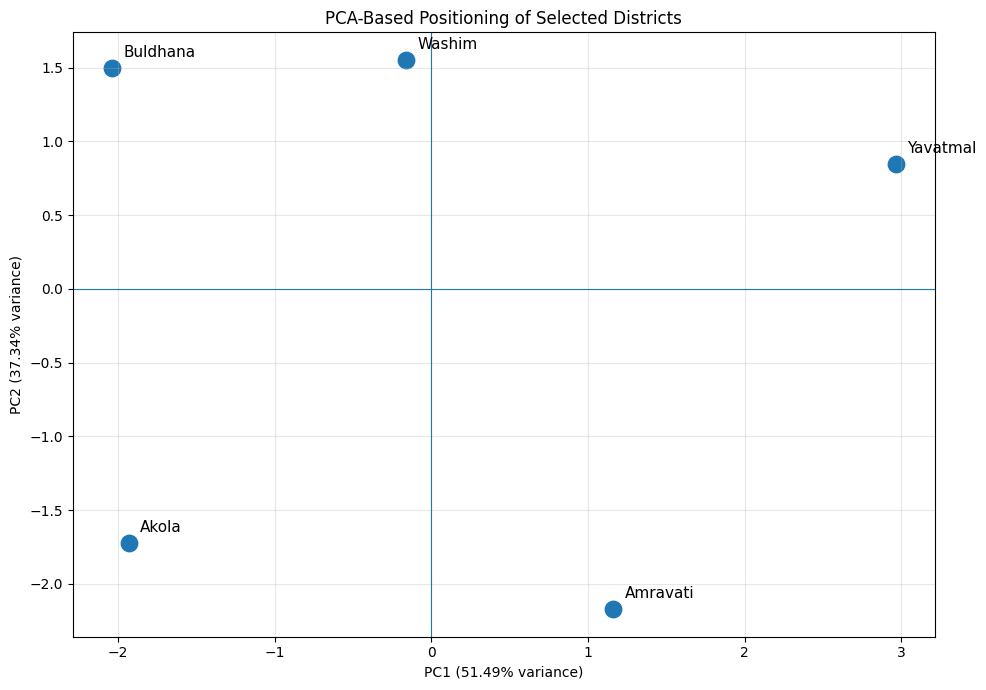

In [ ]:
# ============================================================
# PCA BIPLOT — DISTRICT POSITIONING
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    s=140
)

for district in pca_scores.index:
    x = pca_scores.loc[district, "PC1"]
    y = pca_scores.loc[district, "PC2"]

    plt.annotate(
        district,
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11
    )

# Reference axes
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title(
    "PCA-Based Positioning of Selected Districts"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# FINAL PCA SCORE TABLE
# ============================================================

pca_results = pca_scores.copy()

pca_results = pca_results.reset_index()

display(
    pca_results.round(4)
)

,District,PC1,PC2,PC3,PC4,PC5
0,Amravati,1.1622,-2.1732,0.4460,-0.6027,0.0
1,Yavatmal,2.9634,0.8454,-0.7313,0.2663,-0.0
2,Akola,-1.9272,-1.7239,-0.3391,0.6377,0.0
3,Washim,-0.1616,1.5539,1.2090,0.2808,0.0
4,Buldhana,-2.0368,1.4979,-0.5846,-0.5821,-0.0


In [ ]:
# Save PCA scores
pca_results.to_csv(
    "maharashtra_elnino_pca_scores.csv",
    index=False
)

# Save PCA loadings
loadings.to_csv(
    "maharashtra_elnino_pca_loadings.csv"
)

print("PCA scores and loadings saved successfully.")

PCA scores and loadings saved successfully.


District Cluster Assignments:


,District,PC1,PC2,Cluster
District,,,,
Yavatmal,Yavatmal,2.963403,0.845376,0
Washim,Washim,-0.161586,1.553936,0
Buldhana,Buldhana,-2.036783,1.497853,0
Amravati,Amravati,1.162214,-2.173224,1
Akola,Akola,-1.927247,-1.723940,1


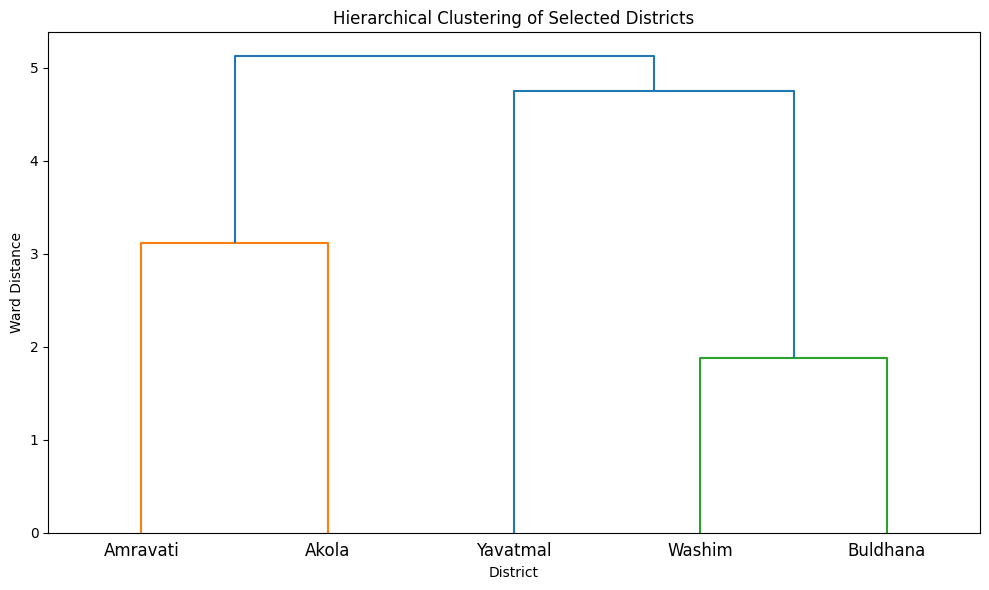

In [ ]:
# ============================================================
# DISTRICT SEGMENTATION USING PCA SCORES
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
import pandas as pd

# Use the first two principal components
pca_cluster_data = pca_scores[['PC1', 'PC2']].copy()

# ------------------------------------------------------------
# Hierarchical clustering
# ------------------------------------------------------------

clustering = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

clusters = clustering.fit_predict(pca_cluster_data)

# Store cluster labels
district_clusters = pca_scores[['PC1', 'PC2']].copy()
district_clusters['District'] = district_clusters.index
district_clusters['Cluster'] = clusters

# Reorder columns
district_clusters = district_clusters[
    ['District', 'PC1', 'PC2', 'Cluster']
]

print("District Cluster Assignments:")
display(district_clusters.sort_values('Cluster'))

# ------------------------------------------------------------
# Hierarchical dendrogram
# ------------------------------------------------------------

Z = linkage(pca_cluster_data, method='ward')

plt.figure(figsize=(10, 6))

dendrogram(
    Z,
    labels=pca_cluster_data.index,
    leaf_rotation=0
)

plt.title("Hierarchical Clustering of Selected Districts")
plt.xlabel("District")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()